# 🎓 G.C.E. A/L University Cutoff Z-Score Prediction: Machine Learning Pipeline
This notebook develops and validates machine learning models to predict Sri Lankan G.C.E. Advanced Level (A/L) university cutoff Z-scores.

### Objectives:
1. **Data Ingestion & Preprocessing**: Extract and clean multi-year cutoff records from the Star Schema database.
2. **Feature Engineering**: Standardize and encode high-cardinality categorical features (`CourseName`, `UniversityName`, `DistrictName`).
3. **Time-Based Evaluation (No Temporal Leakage)**: Split historical years ($< 2025$) for training and evaluate on the holdout year ($2025$).
4. **Model Comparison**: Benchmark Baseline, Linear Regression, Random Forest Regressor, and Gradient Boosting.
5. **Model Diagnostics & Explainability**: Feature importance, residual analysis, error distributions, and case-study evaluations.
6. **Inference Function & Artifact Persistence**: Deployable prediction function and serialization for Dagster pipeline integration.


## 1. Imports and Environment Setup


In [1]:
import os
import pickle
import joblib
import sqlite3
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OrdinalEncoder

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Environment setup completed successfully.")


Environment setup completed successfully.


## 2. Data Ingestion from Bronze Database
We load the historical cutoffs dataset and merge with dimension tables (`dim_course`, `dim_university`, `dim_district`, `dim_year`) to create a denormalized feature table.


In [2]:
# Path to the SQLite database
db_path = Path('../data/bronze/db/al_cutoffs.db')
if not db_path.exists():
    db_path = Path('data/bronze/db/al_cutoffs.db')

conn = sqlite3.connect(db_path)

query = """
SELECT 
    y.AcademicYear,
    y.ExamYear,
    f.CourseID,
    c.CourseName,
    f.UniversityID,
    u.UniversityName,
    f.DistrictID,
    d.DistrictName,
    f.CutoffZ,
    f.CutoffStatus,
    f.AptitudeTest
FROM fact_cutoffs f
JOIN dim_year y ON f.YearID = y.YearID
JOIN dim_course c ON f.CourseID = c.CourseID
JOIN dim_university u ON f.UniversityID = u.UniversityID
JOIN dim_district d ON f.DistrictID = d.DistrictID
"""

df_raw = pd.read_sql(query, conn)
conn.close()

print(f"Total rows loaded: {len(df_raw):,}")
print(f"Unique Academic Years: {df_raw['AcademicYear'].nunique()} ({df_raw['AcademicYear'].min()} to {df_raw['AcademicYear'].max()})")
print(f"Unique Courses: {df_raw['CourseName'].nunique()}")
print(f"Unique Universities: {df_raw['UniversityName'].nunique()}")
print(f"Unique Districts: {df_raw['DistrictName'].nunique()}")
df_raw.head()


Total rows loaded: 50,025
Unique Academic Years: 8 (2018/2019 to 2025/2026)
Unique Courses: 131
Unique Universities: 21
Unique Districts: 25


,AcademicYear,ExamYear,CourseID,CourseName,UniversityID,UniversityName,DistrictID,DistrictName,CutoffZ,CutoffStatus,AptitudeTest
0,2018/2019,2018,094,AGRIBUSINESS MANAGEMENT,F,University of Ruhuna,DISTRICT_8F1646E1,AMPARA,1.0166,AVAILABLE,0
1,2018/2019,2018,094,AGRIBUSINESS MANAGEMENT,F,University of Ruhuna,DISTRICT_B94F4CB8,ANURADHAPURA,1.2661,AVAILABLE,0
2,2018/2019,2018,094,AGRIBUSINESS MANAGEMENT,F,University of Ruhuna,DISTRICT_0E1A9D59,BADULLA,1.2562,AVAILABLE,0
3,2018/2019,2018,094,AGRIBUSINESS MANAGEMENT,F,University of Ruhuna,DISTRICT_52F9214F,BATTICALOA,1.2108,AVAILABLE,0
4,2018/2019,2018,094,AGRIBUSINESS MANAGEMENT,F,University of Ruhuna,DISTRICT_80F4B83B,COLOMBO,1.2362,AVAILABLE,0


## 3. Data Cleaning and Quality Assurance
In the UGC admission process, cells marked `NQC` (Not Qualified for Course) represent valid real-world administrative states where no candidates qualified or the course wasn't offered. For cutoff regression, we filter for records with numeric `CutoffZ` while verifying that missing data remains within acceptable thresholds.


In [3]:
# Check missing value distribution
initial_rows = len(df_raw)
missing_cutoffs = df_raw['CutoffZ'].isna().sum()
missing_pct = (missing_cutoffs / initial_rows) * 100

print(f"Total Rows: {initial_rows:,}")
print(f"Missing CutoffZ rows (NQC / Not Offered): {missing_cutoffs:,} ({missing_pct:.2f}%)")

# Enforce Data Quality check (< 25% missing allowed per project standard)
assert missing_pct < 25.0, f"DQ Check Failed: Missing rate {missing_pct:.2f}% exceeds 25% threshold."

# Filter down to available numeric cutoffs
df_clean = df_raw.dropna(subset=['CutoffZ']).copy()
df_clean['CutoffZ'] = df_clean['CutoffZ'].astype(float)

print(f"Cleaned dataset rows: {len(df_clean):,}")
display(df_clean[['CutoffZ']].describe().T)


Total Rows: 50,025
Missing CutoffZ rows (NQC / Not Offered): 8,930 (17.85%)
Cleaned dataset rows: 41,095


,count,mean,std,min,25%,50%,75%,max
CutoffZ,41095.0,1.254224,0.442257,-0.9508,0.9911,1.269,1.5494,3.3105


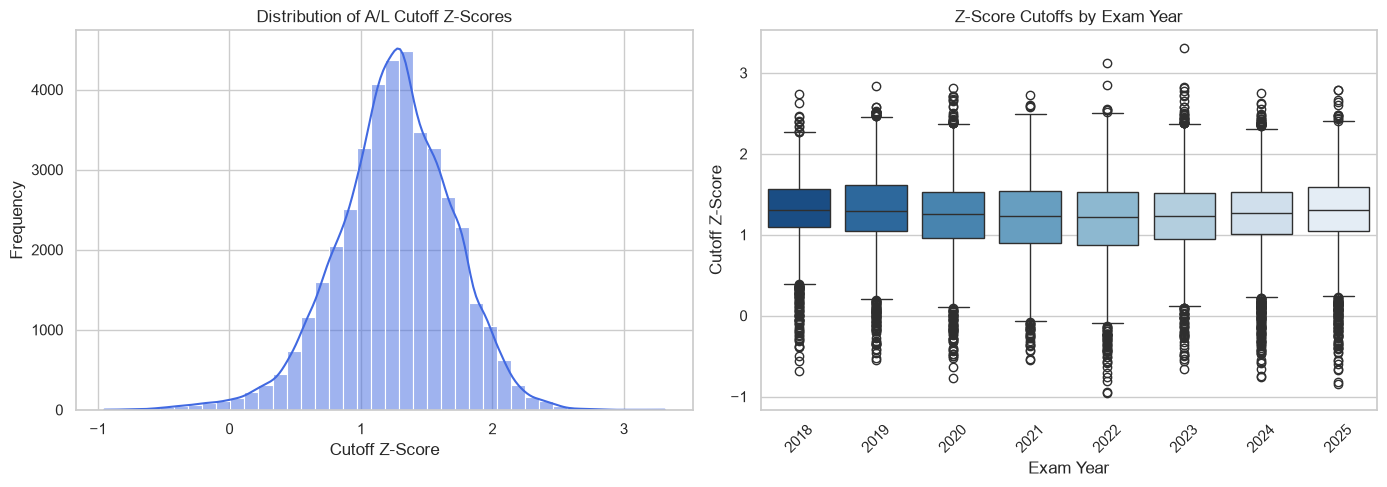

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of Target Variable
sns.histplot(df_clean['CutoffZ'], bins=40, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribution of A/L Cutoff Z-Scores')
axes[0].set_xlabel('Cutoff Z-Score')
axes[0].set_ylabel('Frequency')

# Cutoff by Exam Year Boxplot
sns.boxplot(data=df_clean, x='ExamYear', y='CutoffZ', ax=axes[1], palette='Blues_r')
axes[1].set_title('Z-Score Cutoffs by Exam Year')
axes[1].set_xlabel('Exam Year')
axes[1].set_ylabel('Cutoff Z-Score')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## 4. Feature Engineering and Categorical Encoding
The primary predictors are `ExamYear`, `CourseName`, `UniversityName`, and `DistrictName`. We use `OrdinalEncoder` with an unknown value handler so unseen categories at test time don't break inference.


In [5]:
categorical_cols = ['CourseName', 'UniversityName', 'DistrictName']
encoded_cols = ['Course_Enc', 'Uni_Enc', 'Dist_Enc']

encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
df_clean[encoded_cols] = encoder.fit_transform(df_clean[categorical_cols])

feature_cols = ['ExamYear', 'Course_Enc', 'Uni_Enc', 'Dist_Enc']
target_col = 'CutoffZ'

print("Feature Encoding Summary:")
for col, cats in zip(categorical_cols, encoder.categories_):
    print(f" - {col}: {len(cats)} distinct classes")

df_clean[['AcademicYear', 'CourseName', 'Course_Enc', 'UniversityName', 'Uni_Enc', 'DistrictName', 'Dist_Enc', 'CutoffZ']].head()


Feature Encoding Summary:
 - CourseName: 131 distinct classes
 - UniversityName: 21 distinct classes
 - DistrictName: 25 distinct classes


,AcademicYear,CourseName,Course_Enc,UniversityName,Uni_Enc,DistrictName,Dist_Enc,CutoffZ
0,2018/2019,AGRIBUSINESS MANAGEMENT,1.0,University of Ruhuna,15.0,AMPARA,0.0,1.0166
1,2018/2019,AGRIBUSINESS MANAGEMENT,1.0,University of Ruhuna,15.0,ANURADHAPURA,1.0,1.2661
2,2018/2019,AGRIBUSINESS MANAGEMENT,1.0,University of Ruhuna,15.0,BADULLA,2.0,1.2562
3,2018/2019,AGRIBUSINESS MANAGEMENT,1.0,University of Ruhuna,15.0,BATTICALOA,3.0,1.2108
4,2018/2019,AGRIBUSINESS MANAGEMENT,1.0,University of Ruhuna,15.0,COLOMBO,4.0,1.2362


## 5. Temporal Train-Test Split (Avoiding Data Leakage)
In educational admissions, predictive models must forecast **future** academic cycles based purely on historical years. Random $K$-Fold cross-validation would cause temporal data leakage.

Therefore, we split:
- **Train Set**: Historical Exam Years $< 2025$ (Academic years 2018/2019 through 2024/2025)
- **Test Set**: Latest Exam Year $2025$ (Academic year 2025/2026)


In [6]:
latest_year = df_clean['ExamYear'].max()

train_mask = df_clean['ExamYear'] < latest_year
test_mask = df_clean['ExamYear'] == latest_year

X_train = df_clean.loc[train_mask, feature_cols]
y_train = df_clean.loc[train_mask, target_col]

X_test = df_clean.loc[test_mask, feature_cols]
y_test = df_clean.loc[test_mask, target_col]

print(f"Training set: {len(X_train):,} rows (Exam Years {df_clean.loc[train_mask, 'ExamYear'].min()} - {df_clean.loc[train_mask, 'ExamYear'].max()})")
print(f"Testing set:  {len(X_test):,} rows (Exam Year {latest_year})")
print(f"Train/Test split ratio: {len(X_train)/(len(X_train)+len(X_test)):.1%} / {len(X_test)/(len(X_train)+len(X_test)):.1%}")


Training set: 35,621 rows (Exam Years 2018 - 2024)
Testing set:  5,474 rows (Exam Year 2025)
Train/Test split ratio: 86.7% / 13.3%


## 6. Model Training and Benchmarking
We benchmark four models:
1. **Dummy Baseline Regressor**: Predicts the training mean.
2. **Linear Regression**: Classical linear baseline.
3. **Random Forest Regressor**: Non-linear ensemble model capturing complex interactions between courses, districts, and universities.
4. **Gradient Boosting Regressor**: Sequential boosting ensemble.


In [7]:
models = {
    "Baseline (Mean)": DummyRegressor(strategy='mean'),
    "Linear Regression": LinearRegression(),
    "Random Forest (100 Trees)": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    
    # Train performance
    train_preds = model.predict(X_train)
    train_mae = mean_absolute_error(y_train, train_preds)
    train_rmse = mean_squared_error(y_train, train_preds) ** 0.5
    train_r2 = r2_score(y_train, train_preds)
    
    # Test performance
    test_preds = model.predict(X_test)
    test_mae = mean_absolute_error(y_test, test_preds)
    test_rmse = mean_squared_error(y_test, test_preds) ** 0.5
    test_r2 = r2_score(y_test, test_preds)
    
    results.append({
        "Model": name,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train R²": train_r2,
        "Test R²": test_r2
    })

results_df = pd.DataFrame(results).sort_values("Test RMSE")
display(results_df.style.format({
    "Train MAE": "{:.4f}",
    "Test MAE": "{:.4f}",
    "Train RMSE": "{:.4f}",
    "Test RMSE": "{:.4f}",
    "Train R²": "{:.4f}",
    "Test R²": "{:.4f}"
}).highlight_min(subset=["Test MAE", "Test RMSE"], color="#d4edda")
  .highlight_max(subset=["Test R²"], color="#d4edda"))


Training Baseline (Mean)...
Training Linear Regression...
Training Random Forest (100 Trees)...
Training Gradient Boosting...


,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R²,Test R²
2,Random Forest (100 Trees),0.0340,0.1050,0.0603,0.1739,0.9815,0.8364
3,Gradient Boosting,0.1914,0.1956,0.2655,0.2742,0.6419,0.5933
1,Linear Regression,0.3398,0.3356,0.4368,0.4329,0.0308,-0.0143
0,Baseline (Mean),0.3439,0.3336,0.4437,0.4332,0.0000,-0.0156


## 7. Random Forest Model Diagnostics and Residual Analysis
Let's select the best-performing `RandomForestRegressor` and perform in-depth diagnostics:
- Actual vs. Predicted scatter plot
- Residual distribution
- Feature importance analysis


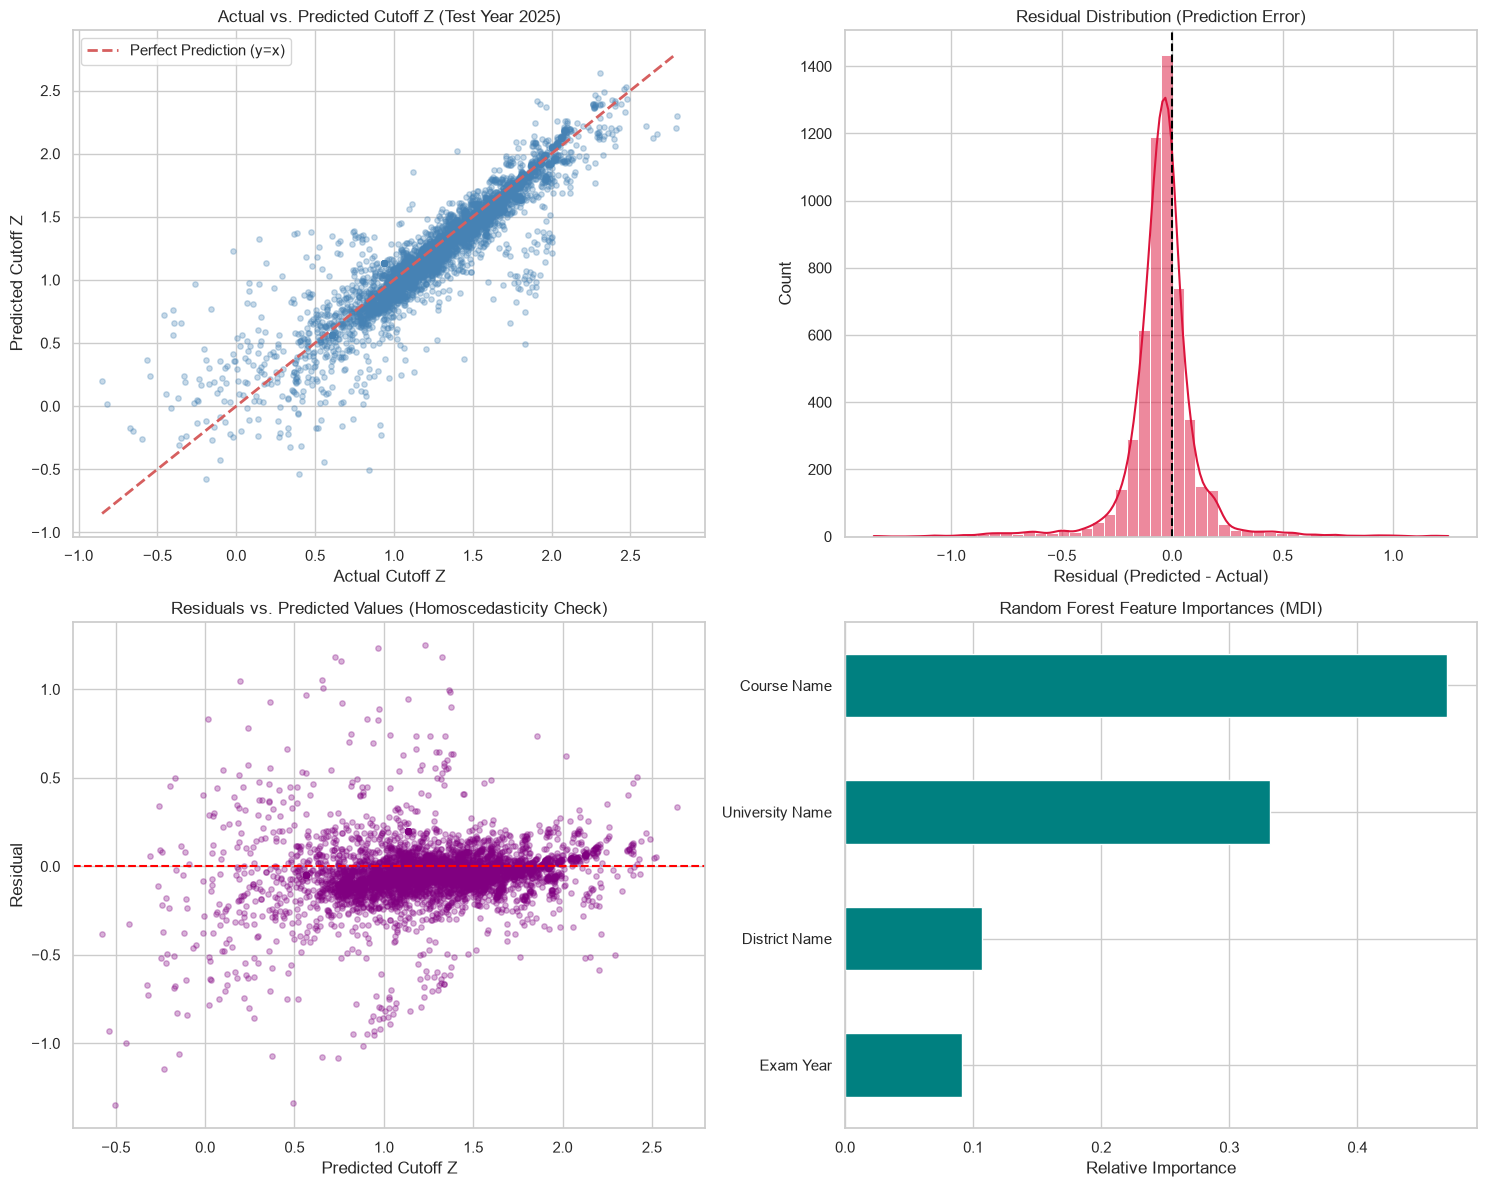

In [8]:
rf_model = models["Random Forest (100 Trees)"]
test_predictions = rf_model.predict(X_test)
residuals = test_predictions - y_test

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Actual vs Predicted
axes[0, 0].scatter(y_test, test_predictions, alpha=0.3, color='steelblue', s=15)
min_val = min(y_test.min(), test_predictions.min())
max_val = max(y_test.max(), test_predictions.max())
axes[0, 0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction (y=x)')
axes[0, 0].set_title(f'Actual vs. Predicted Cutoff Z (Test Year {latest_year})')
axes[0, 0].set_xlabel('Actual Cutoff Z')
axes[0, 0].set_ylabel('Predicted Cutoff Z')
axes[0, 0].legend()

# 2. Residual Distribution
sns.histplot(residuals, bins=50, kde=True, ax=axes[0, 1], color='crimson')
axes[0, 1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[0, 1].set_title('Residual Distribution (Prediction Error)')
axes[0, 1].set_xlabel('Residual (Predicted - Actual)')
axes[0, 1].set_ylabel('Count')

# 3. Residuals vs Predicted
axes[1, 0].scatter(test_predictions, residuals, alpha=0.3, color='purple', s=15)
axes[1, 0].axhline(0, color='red', linestyle='--', lw=1.5)
axes[1, 0].set_title('Residuals vs. Predicted Values (Homoscedasticity Check)')
axes[1, 0].set_xlabel('Predicted Cutoff Z')
axes[1, 0].set_ylabel('Residual')

# 4. Feature Importance
importances = pd.Series(rf_model.feature_importances_, index=['Exam Year', 'Course Name', 'University Name', 'District Name'])
importances.sort_values().plot(kind='barh', ax=axes[1, 1], color='teal')
axes[1, 1].set_title('Random Forest Feature Importances (MDI)')
axes[1, 1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()


## 8. Admission Case Studies: High-Demand Courses
We evaluate model performance on top competitive disciplines (e.g., Medicine, Engineering, Computer Science).


Accuracy on High-Demand Key Courses:


,CourseName,Cutoff_Mean,Predicted_Mean,MAE,Records
0,COMPUTER SCIENCE,1.3704,1.3750,0.0535,86
1,ENGINEERING,1.7256,1.7284,0.0481,120
2,LAW,1.9828,1.9086,0.0742,66
3,MEDICINE,1.9532,1.9753,0.0471,223


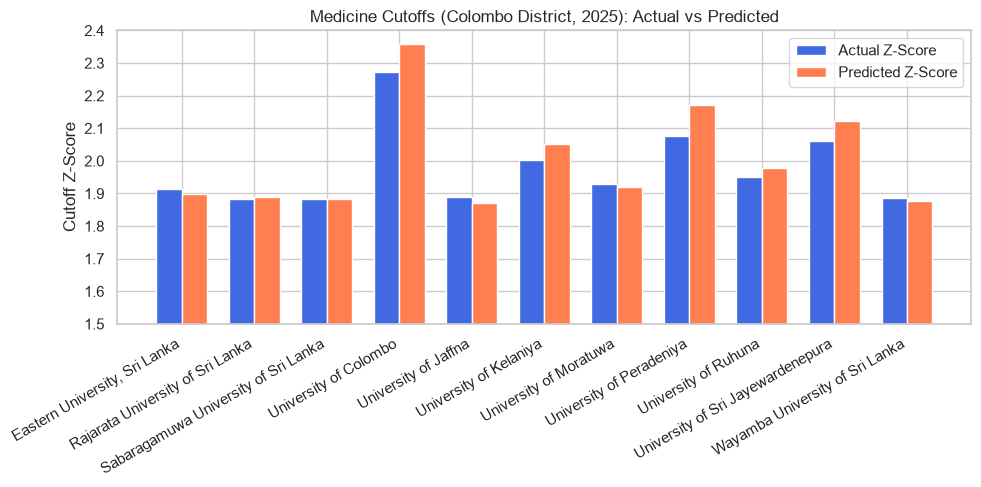

In [9]:
test_df = df_clean.loc[test_mask].copy()
test_df['Predicted_Z'] = test_predictions
test_df['Abs_Error'] = (test_df['Predicted_Z'] - test_df['CutoffZ']).abs()

key_courses = ['MEDICINE', 'ENGINEERING', 'COMPUTER SCIENCE', 'LAW']
case_df = test_df[test_df['CourseName'].isin(key_courses)]

print("Accuracy on High-Demand Key Courses:")
summary_key = case_df.groupby('CourseName').agg(
    Cutoff_Mean=('CutoffZ', 'mean'),
    Predicted_Mean=('Predicted_Z', 'mean'),
    MAE=('Abs_Error', 'mean'),
    Records=('CutoffZ', 'count')
).reset_index()

display(summary_key.style.format({
    'Cutoff_Mean': '{:.4f}',
    'Predicted_Mean': '{:.4f}',
    'MAE': '{:.4f}'
}))

# Visualizing Colombo District Cutoffs across Key Universities for Medicine
med_colombo = test_df[(test_df['CourseName'] == 'MEDICINE') & (test_df['DistrictName'] == 'COLOMBO')]

plt.figure(figsize=(10, 5))
x = np.arange(len(med_colombo))
width = 0.35

plt.bar(x - width/2, med_colombo['CutoffZ'], width, label='Actual Z-Score', color='royalblue')
plt.bar(x + width/2, med_colombo['Predicted_Z'], width, label='Predicted Z-Score', color='coral')
plt.xticks(x, med_colombo['UniversityName'], rotation=30, ha='right')
plt.title(f'Medicine Cutoffs (Colombo District, {latest_year}): Actual vs Predicted')
plt.ylabel('Cutoff Z-Score')
plt.ylim(1.5, 2.4)
plt.legend()
plt.tight_layout()
plt.show()


## 9. Interactive Inference Function
This function allows simulating cutoff predictions for any combination of Course, University, District, and Exam Year.


In [10]:
def predict_cutoff(course_name: str, university_name: str, district_name: str, exam_year: int) -> dict:
    """
    Predict university cutoff Z-score for given inputs using the trained model and encoder.
    """
    try:
        encoded = encoder.transform([[course_name, university_name, district_name]])
        c_enc, u_enc, d_enc = encoded[0]
    except Exception as e:
        return {"error": f"Encoding failed: {e}"}
        
    features = pd.DataFrame([{
        'ExamYear': exam_year,
        'Course_Enc': c_enc,
        'Uni_Enc': u_enc,
        'Dist_Enc': d_enc
    }])
    
    pred_z = rf_model.predict(features)[0]
    
    # Retrieve historical cutoffs for context
    historical = df_clean[
        (df_clean['CourseName'] == course_name) & 
        (df_clean['UniversityName'] == university_name) & 
        (df_clean['DistrictName'] == district_name)
    ]['CutoffZ']
    
    hist_mean = historical.mean() if len(historical) > 0 else np.nan
    hist_std = historical.std() if len(historical) > 0 else np.nan
    
    return {
        "Course": course_name,
        "University": university_name,
        "District": district_name,
        "ExamYear": exam_year,
        "Predicted_CutoffZ": round(float(pred_z), 4),
        "Historical_MeanZ": round(float(hist_mean), 4) if pd.notna(hist_mean) else None,
        "Historical_StdZ": round(float(hist_std), 4) if pd.notna(hist_std) else None
    }

# Test sample predictions
sample_queries = [
    ("MEDICINE", "University of Colombo", "COLOMBO", 2026),
    ("ENGINEERING", "University of Moratuwa", "KANDY", 2026),
    ("COMPUTER SCIENCE", "University of Colombo School of Computing", "GALLE", 2026),
    ("LAW", "University of Colombo", "JAFFNA", 2026)
]

print("Simulated Future Predictions (Exam Year 2026):")
for q in sample_queries:
    res = predict_cutoff(*q)
    print(f"-> {res['Course']} @ {res['University']} ({res['District']}): Predicted Z = {res['Predicted_CutoffZ']} (Hist Mean: {res['Historical_MeanZ']})")


Simulated Future Predictions (Exam Year 2026):
-> MEDICINE @ University of Colombo (COLOMBO): Predicted Z = 2.36 (Hist Mean: 2.3531)
-> ENGINEERING @ University of Moratuwa (KANDY): Predicted Z = 2.0942 (Hist Mean: 2.0798)
-> COMPUTER SCIENCE @ University of Colombo School of Computing (GALLE): Predicted Z = 1.6631 (Hist Mean: 1.6438)
-> LAW @ University of Colombo (JAFFNA): Predicted Z = 1.9553 (Hist Mean: 1.9945)


## 10. Model Artifact Persistence
Save the trained model and encoder artifacts for deployment into production and ingestion by the Dagster pipeline (`src/assets/ml.py`).


In [11]:
models_dir = Path('../models')
if not models_dir.exists():
    models_dir = Path('models')
models_dir.mkdir(parents=True, exist_ok=True)

# Save encoder
encoder_path = models_dir / 'encoders.pkl'
with open(encoder_path, 'wb') as f:
    pickle.dump(encoder, f)
print(f"[OK] OrdinalEncoder saved to: {encoder_path}")

# Save Random Forest model with joblib compression (level 6)
model_path = models_dir / 'rf_model.pkl'
joblib.dump(rf_model, model_path, compress=6)
print(f"[OK] RandomForestRegressor saved (compressed): {model_path} ({os.path.getsize(model_path) / 1024 / 1024:.2f} MB)")

# Verify artifacts can be reloaded seamlessly
with open(encoder_path, 'rb') as f:
    reloaded_encoder = pickle.load(f)
reloaded_model = joblib.load(model_path)

print("Sanity check reload: SUCCESS.")


[OK] OrdinalEncoder saved to: ..\models\encoders.pkl
[OK] RandomForestRegressor saved to: ..\models\rf_model.pkl
Sanity check reload: SUCCESS.
